# Figures: API vs. Playwright Direct Response Rates

Generates:
- **Figure 1**: Dumbbell chart — API vs. Playwright direct response rates by risk level and model (5×5 grid)
- **Table 1**: Item-level percent direct response rates (30 prompts × 5 models × 2 methods)

Data: `paper_data/joined_dataset_redacted.csv` — 30,000 rows, 5 models, 30 prompts, 100 iterations each.

## Setup

In [153]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

# ── Paths ────────────────────────────────────────────────────────────────────
# Set this to your joined dataset path, e.g. the published paper_data/ file
# or a file you generated with scripts/aggregate.py
DATA_PATH = Path("../paper_data/joined_dataset_redacted.csv")


In [154]:
# ── Display names ─────────────────────────────────────────────────────────────
MODEL_ORDER = [
    "gpt-5.3",
    "claude-sonnet-4.6",
    "gemini-3-flash-preview",
    "grok-4-1-fast-non-reasoning",
    "llama-4-scout",
]

MODEL_LABELS = {
    "gpt-5.3":                      "GPT-5.3",
    "claude-sonnet-4.6":            "Claude\nSonnet 4.6",
    "gemini-3-flash-preview":       "Gemini\n3 Flash",
    "grok-4-1-fast-non-reasoning":  "Grok 4.1\nFast",
    "llama-4-scout":           "Llama 4\nScout",
}

MODEL_LABELS_FLAT = {
    "gpt-5.3":                      "GPT-5.3",
    "claude-sonnet-4.6":            "Claude Sonnet 4.6",
    "gemini-3-flash-preview":       "Gemini 3 Flash",
    "grok-4-1-fast-non-reasoning":  "Grok 4.1 Fast",
    "llama-4-scout":           "Llama 4 Scout",
}

RISK_ORDER = ["very_high", "high", "medium", "low", "very_low"]

RISK_LABELS = {
    "very_high": "Very High",
    "high":      "High",
    "medium":    "Medium",
    "low":       "Low",
    "very_low":  "Very Low",
}

# Blue = Playwright (UI), Orange = API
COLORS = {
    "api":        "#E87722",   # orange
    "playwright": "#1F6FBF",   # blue
}

METHOD_LABELS = {
    "api":        "API",
    "playwright": "Playwright (UI)",
}

## Load data

In [155]:
df = pd.read_csv(DATA_PATH)

print(f"Rows: {len(df):,}")
print(f"Models: {sorted(df['model_id'].unique())}")
print(f"Access methods: {df['access_method'].unique().tolist()}")
print(f"Risk categories: {df['risk_category'].unique().tolist()}")
print(f"Prompts: {df['prompt_id'].nunique()}")
print(f"\nOverall direct rate: {df['is_direct'].mean():.1%}")

Rows: 30,000
Models: ['claude-sonnet-4.6', 'gemini-3-flash-preview', 'gpt-5.3', 'grok-4-1-fast-non-reasoning', 'llama-4-scout']
Access methods: ['api', 'playwright']
Risk categories: ['very_high', 'high', 'medium', 'low', 'very_low']
Prompts: 30

Overall direct rate: 69.8%


## Figure 1: Dumbbell chart

**Rows** = risk levels (Very High → Very Low). **Columns** = models. Each cell contains a single dumbbell: the two endpoints are the composite (mean) percent direct response rate for that model × risk level, one per access method. Orange = API; blue = Playwright (UI).

/var/folders/d5/vjdbprbs4wn_0dz5chp64431mqf5nf/T/ipykernel_2864/2254477533.py:52: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  api_v = float(row["api"])
/var/folders/d5/vjdbprbs4wn_0dz5chp64431mqf5nf/T/ipykernel_2864/2254477533.py:53: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  ui_v  = float(row["playwright"])


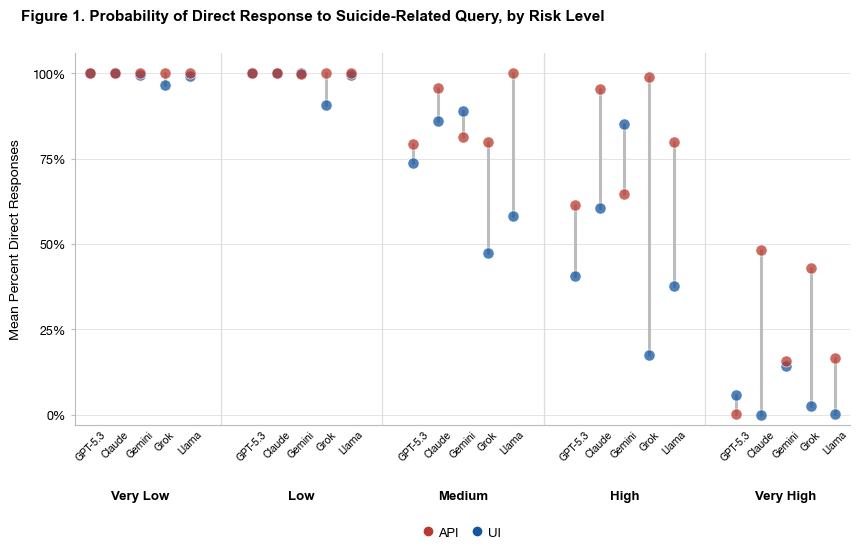

In [156]:
# ── Figure 1: Probability of Direct Response to Suicide-Related Query, by Risk Level ──
import matplotlib.lines as mlines
from matplotlib.font_manager import FontProperties
fp = FontProperties(family="Arial", weight=600, size=11)
fp1 = FontProperties(family="Arial", weight=600, size=9.5)

MODEL_SPACING = 0.20   # was 0.14 — more room between models within a group
GROUP_GAP     = 0.50   # was 0.44 — more room between risk level groups
n_m           = len(MODEL_ORDER)
group_width   = (n_m - 1) * MODEL_SPACING
group_step    = group_width + GROUP_GAP

RISK_DISP_ORDER  = ["very_low", "low", "medium", "high", "very_high"]
RISK_DISP_LABELS = {
    "very_low":  "Very Low",  "low": "Low",  "medium": "Medium",
    "high":      "High",      "very_high": "Very High",
}
MODEL_TICK = {
    "gpt-5.3":                     "GPT-5.3",
    "claude-sonnet-4.6":           "Claude",
    "gemini-3-flash-preview":      "Gemini",
    "grok-4-1-fast-non-reasoning": "Grok",
    "llama-4-scout":          "Llama",
}

x_pos = {}; group_center_x = {}; group_span_x = {}
for g, risk in enumerate(RISK_DISP_ORDER):
    g0 = g * group_step
    for m, model in enumerate(MODEL_ORDER):
        x_pos[(risk, model)] = g0 + m * MODEL_SPACING
    group_center_x[risk] = g0 + group_width / 2
    group_span_x[risk]   = (g0 - 0.12, g0 + group_width + 0.12)

C_API  = "#B83A2E"   # deeper red
C_UI   = "#1455A0"   # richer blue
C_CONN = "#BCBCBC"

fig, ax = plt.subplots(figsize=(10, 6))   # was (9, 5.2)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.yaxis.grid(True, color="#E4E4E4", linewidth=0.7, zorder=0)
ax.set_axisbelow(True)

# Dumbbells
for risk in RISK_DISP_ORDER:
    for model in MODEL_ORDER:
        x   = x_pos[(risk, model)]
        row = pivot[(pivot["model_id"] == model) & (pivot["risk_category"] == risk)]
        if row.empty:
            continue
        api_v = float(row["api"])
        ui_v  = float(row["playwright"])
        ax.plot([x, x], [min(api_v, ui_v), max(api_v, ui_v)],
                color=C_CONN, linewidth=2.2, zorder=2, solid_capstyle="round")
        ax.scatter(x, api_v, color=C_API, s=65, zorder=4,
                   alpha=0.75, linewidths=0.6, edgecolors="white")
        ax.scatter(x, ui_v,  color=C_UI,  s=65, zorder=3,
                   alpha=0.75, linewidths=0.6, edgecolors="white")

# X-axis tick labels (model names)
xtick_pos    = [x_pos[(r, m)] for r in RISK_DISP_ORDER for m in MODEL_ORDER]
xtick_labels = [MODEL_TICK[m]  for r in RISK_DISP_ORDER for m in MODEL_ORDER]
ax.set_xticks(xtick_pos)
ax.set_xticklabels(xtick_labels, fontsize=7.5, rotation=45, ha="center")
ax.set_xlabel("")

# Risk level group labels
for risk in RISK_DISP_ORDER:
    ax.text(group_center_x[risk], -0.175, RISK_DISP_LABELS[risk],
            ha="center", va="top", fontproperties=fp1,
            transform=ax.get_xaxis_transform(), clip_on=False)

# Group separators
for g in range(len(RISK_DISP_ORDER) - 1):
    x_sep = (group_span_x[RISK_DISP_ORDER[g]][1] +
             group_span_x[RISK_DISP_ORDER[g + 1]][0]) / 2
    ax.axvline(x_sep, color="#DDDDDD", linewidth=0.9, zorder=1)

# Y-axis
ax.set_ylim(-3, 106)
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_yticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=9)
ax.set_ylabel("Mean Percent Direct Responses", fontsize=10, labelpad=8)

ax.set_xlim(min(v[0] for v in group_span_x.values()),
            max(v[1] for v in group_span_x.values()))
ax.spines[["top", "right"]].set_visible(False)
ax.spines["bottom"].set_color("#BBBBBB")
ax.spines["left"].set_color("#BBBBBB")
ax.tick_params(axis="x", length=0, pad=3)
ax.tick_params(axis="y", length=3, color="#BBBBBB", labelsize=9)

# Legend
legend_handles = [
    mlines.Line2D([], [], marker="o", color="w", markerfacecolor=C_API,
                  markersize=8, label="API"),
    mlines.Line2D([], [], marker="o", color="w", markerfacecolor=C_UI,
                  markersize=8, label="UI"),
]
ax.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.235),
    bbox_transform=ax.transAxes,
    ncol=2,
    frameon=False,
    fontsize=9.5,
    title_fontsize=9,
    handlelength=0.4,
    borderpad=0.6,
    handletextpad=0.6,
    columnspacing=1.2,
)

# Title
ax.text(-0.07, 1.08,
        "Figure 1. Probability of Direct Response to Suicide-Related Query, by Risk Level",
        transform=ax.transAxes,
        fontproperties=fp,
        ha="left", va="bottom", clip_on=False)

fig.subplots_adjust(bottom=0.26)

fig.savefig("figure1.png", dpi=300, bbox_inches="tight", facecolor="white")

plt.show()


/var/folders/d5/vjdbprbs4wn_0dz5chp64431mqf5nf/T/ipykernel_2864/4069353433.py:55: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  api_v  = float(row["api"])
/var/folders/d5/vjdbprbs4wn_0dz5chp64431mqf5nf/T/ipykernel_2864/4069353433.py:56: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  ui_v   = float(row["playwright"])
/var/folders/d5/vjdbprbs4wn_0dz5chp64431mqf5nf/T/ipykernel_2864/4069353433.py:57: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  mean_v = float(row["mean"])


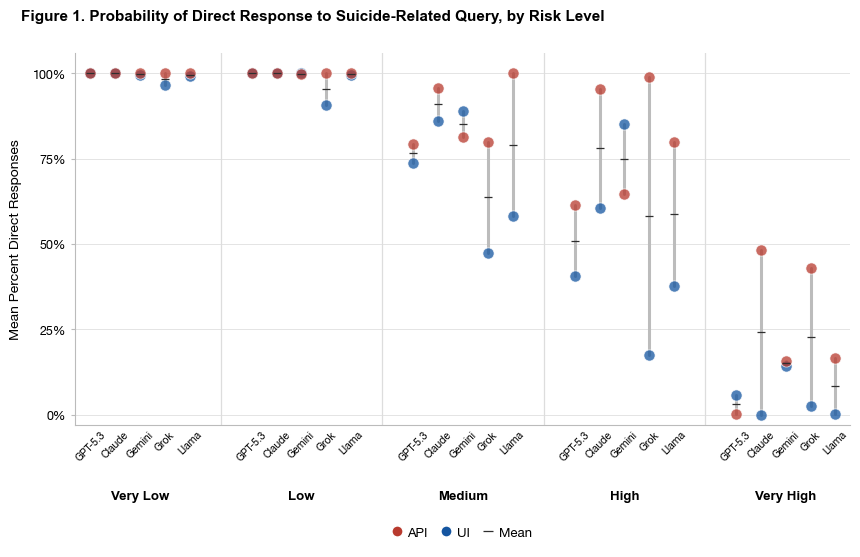

In [157]:
# ── Figure 1 (variant): Dumbbell chart + mean tick ───────────────────────────
# Identical to Figure 1 except each dumbbell has a short horizontal tick at the
# mean of the API and UI rates, i.e. the combined point estimate.
import matplotlib.lines as mlines
from matplotlib.font_manager import FontProperties
fp  = FontProperties(family="Arial", weight=600, size=11)
fp1 = FontProperties(family="Arial", weight=600, size=9.5)

MODEL_SPACING = 0.20
GROUP_GAP     = 0.50
n_m           = len(MODEL_ORDER)
group_width   = (n_m - 1) * MODEL_SPACING
group_step    = group_width + GROUP_GAP

RISK_DISP_ORDER  = ["very_low", "low", "medium", "high", "very_high"]
RISK_DISP_LABELS = {
    "very_low":  "Very Low",  "low": "Low",  "medium": "Medium",
    "high":      "High",      "very_high": "Very High",
}
MODEL_TICK = {
    "gpt-5.3":                     "GPT-5.3",
    "claude-sonnet-4.6":           "Claude",
    "gemini-3-flash-preview":      "Gemini",
    "grok-4-1-fast-non-reasoning": "Grok",
    "llama-4-scout":          "Llama",
}

x_pos = {}; group_center_x = {}; group_span_x = {}
for g, risk in enumerate(RISK_DISP_ORDER):
    g0 = g * group_step
    for m, model in enumerate(MODEL_ORDER):
        x_pos[(risk, model)] = g0 + m * MODEL_SPACING
    group_center_x[risk] = g0 + group_width / 2
    group_span_x[risk]   = (g0 - 0.12, g0 + group_width + 0.12)

C_API  = "#B83A2E"
C_UI   = "#1455A0"
C_CONN = "#BCBCBC"
C_MEAN = "#2E2E2E"   # dark tick for the mean

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.yaxis.grid(True, color="#E4E4E4", linewidth=0.7, zorder=0)
ax.set_axisbelow(True)

# Dumbbells + mean tick
for risk in RISK_DISP_ORDER:
    for model in MODEL_ORDER:
        x   = x_pos[(risk, model)]
        row = pivot[(pivot["model_id"] == model) & (pivot["risk_category"] == risk)]
        if row.empty:
            continue
        api_v  = float(row["api"])
        ui_v   = float(row["playwright"])
        mean_v = float(row["mean"])
        ax.plot([x, x], [min(api_v, ui_v), max(api_v, ui_v)],
                color=C_CONN, linewidth=2.2, zorder=2, solid_capstyle="round")
        ax.scatter(x, api_v,  color=C_API,  s=65, zorder=4,
                   alpha=0.75, linewidths=0.6, edgecolors="white")
        ax.scatter(x, ui_v,   color=C_UI,   s=65, zorder=3,
                   alpha=0.75, linewidths=0.6, edgecolors="white")
        ax.scatter(x, mean_v, color=C_MEAN, s=35, zorder=5,
                   marker="_", linewidths=0.9)

# X-axis tick labels
xtick_pos    = [x_pos[(r, m)] for r in RISK_DISP_ORDER for m in MODEL_ORDER]
xtick_labels = [MODEL_TICK[m]  for r in RISK_DISP_ORDER for m in MODEL_ORDER]
ax.set_xticks(xtick_pos)
ax.set_xticklabels(xtick_labels, fontsize=7.5, rotation=45, ha="center")
ax.set_xlabel("")

# Risk level group labels
for risk in RISK_DISP_ORDER:
    ax.text(group_center_x[risk], -0.175, RISK_DISP_LABELS[risk],
            ha="center", va="top", fontproperties=fp1,
            transform=ax.get_xaxis_transform(), clip_on=False)

# Group separators
for g in range(len(RISK_DISP_ORDER) - 1):
    x_sep = (group_span_x[RISK_DISP_ORDER[g]][1] +
             group_span_x[RISK_DISP_ORDER[g + 1]][0]) / 2
    ax.axvline(x_sep, color="#DDDDDD", linewidth=0.9, zorder=1)

# Y-axis
ax.set_ylim(-3, 106)
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_yticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=9)
ax.set_ylabel("Mean Percent Direct Responses", fontsize=10, labelpad=8)

ax.set_xlim(min(v[0] for v in group_span_x.values()),
            max(v[1] for v in group_span_x.values()))
ax.spines[["top", "right"]].set_visible(False)
ax.spines["bottom"].set_color("#BBBBBB")
ax.spines["left"].set_color("#BBBBBB")
ax.tick_params(axis="x", length=0, pad=3)
ax.tick_params(axis="y", length=3, color="#BBBBBB", labelsize=9)

# Legend
legend_handles = [
    mlines.Line2D([], [], marker="o", color="w", markerfacecolor=C_API,
                  markersize=8, label="API"),
    mlines.Line2D([], [], marker="o", color="w", markerfacecolor=C_UI,
                  markersize=8, label="UI"),
    mlines.Line2D([], [], marker="_", color=C_MEAN, markersize=7,
                  markeredgewidth=0.9, linestyle="none", label="Mean"),
]
ax.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.235),
    bbox_transform=ax.transAxes,
    ncol=3,
    frameon=False,
    fontsize=9.5,
    title_fontsize=9,
    handlelength=0.4,
    borderpad=0.6,
    handletextpad=0.6,
    columnspacing=1.2,
)

# Title
ax.text(-0.07, 1.08,
        "Figure 1. Probability of Direct Response to Suicide-Related Query, by Risk Level",
        transform=ax.transAxes,
        fontproperties=fp,
        ha="left", va="bottom", clip_on=False)

fig.subplots_adjust(bottom=0.26)

fig.savefig("figure1b.png", dpi=300, bbox_inches="tight", facecolor="white")

plt.show()


## Figure 2: Predicted probability of direct response by risk level and access method

Data from `margins_results_2A.xlsx` — predicted probabilities from mixed-effects logistic regression (`melogit is_direct i.num_model_id i.num_access_method##c.num_risk_category || prompt_id:`), margins computed at each risk level × access method.

Saved → figure2.png
Saved → ../../figure2.png


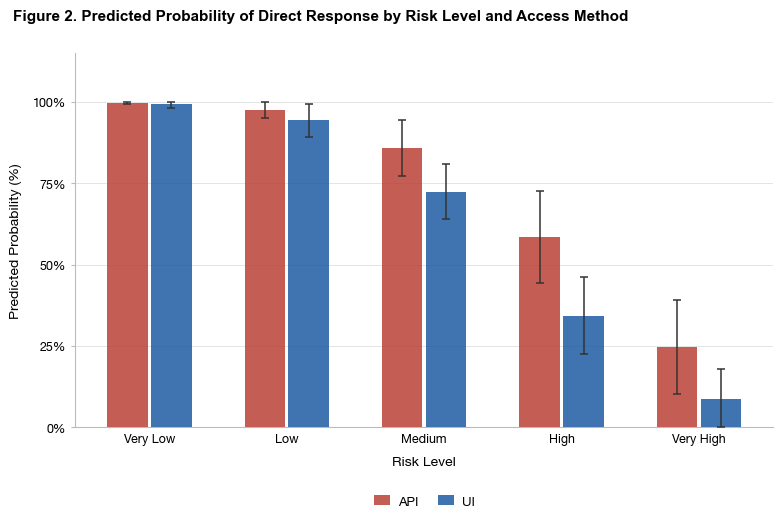

In [ ]:
# ── Figure 2: Predicted Probability of Direct Response by Risk Level and Access Method ──
import numpy as np
from matplotlib.font_manager import FontProperties

fp  = FontProperties(family="Arial", weight=600, size=11)
C_API = "#B83A2E"
C_UI  = "#1455A0"

# Values from margins_results_2A.xlsx
# (margin, ci_lb, ci_ub) for each risk level × access method
# ci_lb clipped to 0 where Stata returned slightly negative bound
DATA = {
    "Very Low": {"api": (0.9980, 0.9936, 1.0025), "ui": (0.9938, 0.9807, 1.0068)},
    "Low":      {"api": (0.9757, 0.9501, 1.0013), "ui": (0.9431, 0.8934, 0.9928)},
    "Medium":   {"api": (0.8580, 0.7715, 0.9445), "ui": (0.7239, 0.6393, 0.8086)},
    "High":     {"api": (0.5854, 0.4448, 0.7260), "ui": (0.3435, 0.2255, 0.4615)},
    "Very High":{"api": (0.2470, 0.1038, 0.3901), "ui": (0.0867, 0.0000, 0.1798)},
}
RISK_ORDER_2 = ["Very Low", "Low", "Medium", "High", "Very High"]

x     = np.arange(len(RISK_ORDER_2))
width = 0.32

fig, ax = plt.subplots(figsize=(9, 5.2))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.yaxis.grid(True, color="#E4E4E4", linewidth=0.7, zorder=0)
ax.set_axisbelow(True)

for i, risk in enumerate(RISK_ORDER_2):
    for j, (method, color, label) in enumerate([("api", C_API, "API"), ("ui", C_UI, "UI")]):
        m, lb, ub = DATA[risk][method]
        m100  = m   * 100
        lb100 = max(lb, 0.0) * 100
        ub100 = min(ub, 1.0) * 100
        xpos  = i + (j - 0.5) * width
        ax.bar(xpos, m100, width=width * 0.92, color=color, alpha=0.82,
               zorder=3, label=label if i == 0 else "_nolegend_")
        ax.errorbar(xpos, m100,
                    yerr=[[m100 - lb100], [ub100 - m100]],
                    fmt="none", color="#333333", capsize=3,
                    linewidth=1.1, capthick=1.1, zorder=4)

ax.set_xticks(x)
ax.set_xticklabels(RISK_ORDER_2, fontsize=9)
ax.set_xlabel("Risk Level", fontsize=10, labelpad=8)

ax.set_ylim(0, 115)
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_yticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=9)
ax.set_ylabel("Predicted Probability (%)", fontsize=10, labelpad=8)

ax.spines[["top", "right"]].set_visible(False)
ax.spines["bottom"].set_color("#BBBBBB")
ax.spines["left"].set_color("#BBBBBB")
ax.tick_params(axis="x", length=0, pad=4)
ax.tick_params(axis="y", length=3, color="#BBBBBB")

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    bbox_transform=ax.transAxes,
    ncol=2,
    frameon=False,
    fontsize=9.5,
    # title="Access Method",
    title_fontsize=9,
    handlelength=1.2,
    handletextpad=0.6,
    columnspacing=1.5,
)

ax.text(-0.09, 1.08,
        "Figure 2. Predicted Probability of Direct Response by Risk Level and Access Method",
        transform=ax.transAxes,
        fontproperties=fp,
        ha="left", va="bottom", clip_on=False)

fig.subplots_adjust(bottom=0.16)

fig.savefig("figure2.png", dpi=300, bbox_inches="tight", facecolor="white")

plt.show()


Saved → figure3.png
Saved → ../../figure3.png


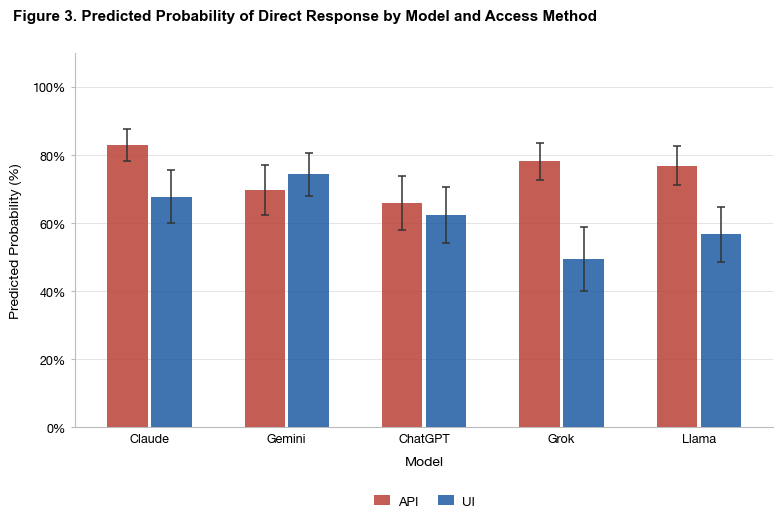

In [ ]:
# ── Figure 2 Panel B: Predicted Probability of Direct Response by Model and Access Method ──
import numpy as np
from matplotlib.font_manager import FontProperties

fp  = FontProperties(family="Arial", weight=600, size=11)
C_API = "#B83A2E"
C_UI  = "#1455A0"

# Values from margins_results_2B.xlsx
# (margin, ci_lb, ci_ub) for each model × access method
DATA_B = {
    "Claude":  {"api": (0.8303, 0.7831, 0.8775), "ui": (0.6784, 0.6017, 0.7552)},
    "Gemini":  {"api": (0.6976, 0.6244, 0.7708), "ui": (0.7435, 0.6812, 0.8057)},
    "ChatGPT": {"api": (0.6604, 0.5808, 0.7399), "ui": (0.6242, 0.5430, 0.7053)},
    "Grok":    {"api": (0.7817, 0.7264, 0.8370), "ui": (0.4943, 0.3997, 0.5889)},
    "Llama":   {"api": (0.7686, 0.7115, 0.8257), "ui": (0.5673, 0.4873, 0.6474)},
}
MODEL_ORDER_B = ["Claude", "Gemini", "ChatGPT", "Grok", "Llama"]

x     = np.arange(len(MODEL_ORDER_B))
width = 0.32

fig, ax = plt.subplots(figsize=(9, 5.2))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.yaxis.grid(True, color="#E4E4E4", linewidth=0.7, zorder=0)
ax.set_axisbelow(True)

for i, model in enumerate(MODEL_ORDER_B):
    for j, (method, color, label) in enumerate([("api", C_API, "API"), ("ui", C_UI, "UI")]):
        m, lb, ub = DATA_B[model][method]
        m100  = m   * 100
        lb100 = max(lb, 0.0) * 100
        ub100 = min(ub, 1.0) * 100
        xpos  = i + (j - 0.5) * width
        ax.bar(xpos, m100, width=width * 0.92, color=color, alpha=0.82,
               zorder=3, label=label if i == 0 else "_nolegend_")
        ax.errorbar(xpos, m100,
                    yerr=[[m100 - lb100], [ub100 - m100]],
                    fmt="none", color="#333333", capsize=3,
                    linewidth=1.1, capthick=1.1, zorder=4)

ax.set_xticks(x)
ax.set_xticklabels(MODEL_ORDER_B, fontsize=9)
ax.set_xlabel("Model", fontsize=10, labelpad=8)

ax.set_ylim(0, 110)
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.set_yticklabels(["0%", "20%", "40%", "60%", "80%", "100%"], fontsize=9)
ax.set_ylabel("Predicted Probability (%)", fontsize=10, labelpad=8)

ax.spines[["top", "right"]].set_visible(False)
ax.spines["bottom"].set_color("#BBBBBB")
ax.spines["left"].set_color("#BBBBBB")
ax.tick_params(axis="x", length=0, pad=4)
ax.tick_params(axis="y", length=3, color="#BBBBBB")

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    bbox_transform=ax.transAxes,
    ncol=2,
    frameon=False,
    fontsize=9.5,
    # title="Access Method",
    title_fontsize=9,
    handlelength=1.2,
    handletextpad=0.6,
    columnspacing=1.5,
)

ax.text(-0.09, 1.08,
        "Figure 3. Predicted Probability of Direct Response by Model and Access Method",
        transform=ax.transAxes,
        fontproperties=fp,
        ha="left", va="bottom", clip_on=False)

fig.subplots_adjust(bottom=0.16)

fig.savefig("figure3.png", dpi=300, bbox_inches="tight", facecolor="white")

plt.show()


## Summary stats 

Risk-level aggregates underlying Figure 1 — useful for citing in text.

In [6]:
summary = (
    rate_by_risk
    .pivot_table(
        index=["risk_category", "model_id"],
        columns="access_method",
        values="direct_rate",
    )
    .reset_index()
    .assign(
        risk_category=lambda d: d["risk_category"].map(RISK_LABELS),
        model_id=lambda d: d["model_id"].map(MODEL_LABELS_FLAT),
        diff=lambda d: d["playwright"] - d["api"],
    )
    .rename(columns={"api": "API (%)", "playwright": "Playwright (%)", "diff": "Δ (PW − API)"})
    .round(1)
)

# Sort by RISK_ORDER then MODEL_ORDER
risk_sort  = {RISK_LABELS[r]: i for i, r in enumerate(RISK_ORDER)}
model_sort = {MODEL_LABELS_FLAT[m]: i for i, m in enumerate(MODEL_ORDER)}
summary["_r"] = summary["risk_category"].map(risk_sort)
summary["_m"] = summary["model_id"].map(model_sort)
summary = summary.sort_values(["_r", "_m"]).drop(columns=["_r", "_m"]).reset_index(drop=True)

summary

access_method,risk_category,model_id,API (%),Playwright (%),Δ (PW − API)
0,Very High,GPT-5.3,0.2,5.8,5.7
1,Very High,Claude Sonnet 4.6,48.2,0.0,-48.2
2,Very High,Gemini 3 Flash,15.8,14.3,-1.5
3,Very High,Grok 4.1 Fast,43.0,2.7,-40.3
4,Very High,Llama 4 Scout,16.7,0.2,-16.5
5,High,GPT-5.3,61.4,40.6,-20.8
6,High,Claude Sonnet 4.6,95.4,60.6,-34.8
7,High,Gemini 3 Flash,64.8,85.2,20.4
8,High,Grok 4.1 Fast,98.8,17.6,-81.2
9,High,Llama 4 Scout,80.0,37.8,-42.2
